# Week 3 — Enhanced Feature Set
### Modeling Disagreement in LLM Harm Annotation

---

**Goal:** Improve our linear regression model by adding more features.

**Previously used features:**
- Annotator: Gender, Age, Political_Affiliation, Education, Factor_1/2/3
- Prompt: Harm_Level, value_topic_* (39 columns)

**New features added:**

| Feature Group | Columns | Why? |
|---|---|---|
| `action_*` | 16 columns | Different harm types affect people differently |
| `effect_*` | 7 columns | Psychological/physical effects resonate differently |
| `Religion_Importance` | 1 column | Religious values may influence harm perception |
| `Trial_*` | 1 per prompt | Order effect — fatigue may affect later ratings |
| `Social_Media_Frequency` | 1 column | Online experience shapes harm sensitivity |
| `Toxicity_Experience` | 1 column | Prior toxicity exposure affects judgment |
| `Income` | 1 column | Socioeconomic background may influence values |


## 0. Setup

In [9]:
import sys, os, warnings
warnings.filterwarnings('ignore')

def find_repo_root():
    current = os.path.abspath(os.getcwd())
    for _ in range(5):
        if os.path.exists(os.path.join(current, 'data', 'annotations.csv')):
            return current
        current = os.path.dirname(current)
    raise FileNotFoundError("Cannot find repo root.")

REPO_ROOT = find_repo_root()
sys.path.insert(0, os.path.join(REPO_ROOT, 'src'))
os.chdir(REPO_ROOT)
os.makedirs("outputs", exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import train_test_split

from data_loader import load_data, get_rating_columns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 110

print("All libraries loaded successfully.")

All libraries loaded successfully.


## 1. Load Data

In [10]:
annotations, prompts = load_data()
rating_cols = get_rating_columns(annotations)

print(f"annotations : {annotations.shape}")
print(f"prompts     : {prompts.shape}")

annotations : (100, 314)
prompts     : (150, 65)


## 2. Define Feature Groups

We now use a much richer set of features compared to our baseline model.


In [11]:
# ── Annotator features ────────────────────────────────────────
# Categorical (will be one-hot encoded)
demo_cols = [
    'Gender',
    'Age',
    'Political_Affiliation',
    'Education',
    'Social_Media_Frequency',   # NEW
    'Toxicity_Experience',       # NEW
    'Income',                    # NEW
]

# Numerical (used directly)
factor_cols   = ['Factor_1', 'Factor_2', 'Factor_3']
religion_cols = ['Religion_Importance']   # NEW — numerical

# ── Prompt features ───────────────────────────────────────────
value_cols  = [c for c in prompts.columns if c.startswith('value_topic_')]
action_cols = [c for c in prompts.columns if c.startswith('action_')]    # NEW
effect_cols = [c for c in prompts.columns if c.startswith('effect_')]    # NEW

prompt_num_cols = ['Harm_Level'] + value_cols + action_cols + effect_cols

print(f"Demographic (categorical) : {len(demo_cols)} columns")
print(f"Factor scores             : {len(factor_cols)} columns")
print(f"Religion importance       : {len(religion_cols)} column")
print(f"Value topics              : {len(value_cols)} columns")
print(f"Action categories (NEW)   : {len(action_cols)} columns")
print(f"Effect categories (NEW)   : {len(effect_cols)} columns")
print(f"\nTotal prompt features     : {len(prompt_num_cols)}")
print(f"Total annotator features  : {len(demo_cols) + len(factor_cols) + len(religion_cols)}")

Demographic (categorical) : 7 columns
Factor scores             : 3 columns
Religion importance       : 1 column
Value topics              : 39 columns
Action categories (NEW)   : 16 columns
Effect categories (NEW)   : 7 columns

Total prompt features     : 63
Total annotator features  : 11


## 3. Convert to Long Format

Same as before: 100 annotators × 150 prompts = 15,000 rows.

**New addition:** We also include the `Trial` score for each annotator-prompt pair.
The Trial score tells us the order in which this annotator saw this prompt.
A lower Trial score = seen earlier. This captures potential fatigue or order effects.


In [12]:
# Trial columns: Trial_1 corresponds to Rating_1, etc.
trial_cols = [c for c in annotations.columns if c.startswith('Trial_')]

rows = []
for _, ann_row in annotations.iterrows():
    for col in rating_cols:
        q_idx  = int(col.replace('Rating_', ''))
        rating = ann_row[col]

        if pd.isna(rating):
            continue

        prompt_row = prompts[prompts['Question_Index'] == q_idx]
        if len(prompt_row) == 0:
            continue

        row = {
            'rating'        : rating,
            'Participant_ID': ann_row['Participant_ID'],
        }

        # Annotator features
        for c in demo_cols + factor_cols + religion_cols:
            row[c] = ann_row[c]

        # Trial score (order effect) — NEW
        trial_col = f'Trial_{q_idx}'
        if trial_col in ann_row.index:
            row['trial_order'] = ann_row[trial_col]
        else:
            row['trial_order'] = np.nan

        # Prompt features
        for c in prompt_num_cols:
            row[c] = prompt_row[c].values[0]

        rows.append(row)

long_df = pd.DataFrame(rows)

print(f"Long format: {long_df.shape[0]:,} rows x {long_df.shape[1]} columns")
print(f"NaN in trial_order: {long_df['trial_order'].isna().sum()}")
long_df[['Participant_ID', 'rating', 'Gender', 'Factor_1',
         'Harm_Level', 'trial_order', 'action_Child_Harm']].head(3)

Long format: 14,725 rows x 77 columns
NaN in trial_order: 0


,Participant_ID,rating,Gender,Factor_1,Harm_Level,trial_order,action_Child_Harm
0,0,65.0,Man,-8.232909,0.5,10,0.0
1,0,60.0,Man,-8.232909,0.6,92,0.0
2,0,63.0,Man,-8.232909,0.7,81,0.0


## 4. Encode Categorical Variables

We one-hot encode all categorical columns.
Numerical columns (factors, harm level, value topics, action/effect flags) are used as-is.


In [13]:
# Add Religion_Importance to categorical columns to encode
demo_cols_encode = demo_cols + ['Religion_Importance']

long_df_encoded = pd.get_dummies(long_df, columns=demo_cols_encode, drop_first=True)

# Fill any remaining NaN values with median
long_df_encoded = long_df_encoded.fillna(long_df_encoded.median(numeric_only=True))

feature_cols = [c for c in long_df_encoded.columns
                if c not in ['rating', 'Participant_ID']]

y = long_df_encoded['rating']
X = long_df_encoded[feature_cols]

print(f"Total features: {len(feature_cols)}")

Total features: 97


## 5. Train / Test Split

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training set : {X_train.shape[0]:,} rows")
print(f"Test set     : {X_test.shape[0]:,} rows")

Training set : 11,780 rows
Test set     : 2,945 rows


## 6. Baseline Model (Previous Features)

We re-run the old model with the same limited features to compare fairly.


In [15]:
# Old feature set
old_demo_cols   = ['Gender', 'Age', 'Political_Affiliation', 'Education']
old_prompt_cols = ['Harm_Level'] + value_cols
old_factor_cols = ['Factor_1', 'Factor_2', 'Factor_3']

old_features = [c for c in feature_cols
                if any(c.startswith(d + '_') for d in old_demo_cols)
                or c in old_prompt_cols
                or c in old_factor_cols]

baseline = LinearRegression()
baseline.fit(X_train[old_features], y_train)
pred_base  = baseline.predict(X_test[old_features])
r2_base    = r2_score(y_test, pred_base)
rmse_base  = np.sqrt(mean_squared_error(y_test, pred_base))

print(f"Baseline model ({len(old_features)} features):")
print(f"  R²   = {r2_base:.3f}")
print(f"  RMSE = {rmse_base:.2f}")

Baseline model (58 features):
  R²   = 0.257
  RMSE = 32.42


## 7. Enhanced Model (All Features)

Now we train with all features including the new ones.


In [16]:
enhanced = LinearRegression()
enhanced.fit(X_train, y_train)
pred_enh  = enhanced.predict(X_test)
r2_enh    = r2_score(y_test, pred_enh)
rmse_enh  = np.sqrt(mean_squared_error(y_test, pred_enh))

print(f"Enhanced model ({len(feature_cols)} features):")
print(f"  R²   = {r2_enh:.3f}")
print(f"  RMSE = {rmse_enh:.2f}")
print()
print(f"R² improvement: {r2_base:.3f} → {r2_enh:.3f} (+{(r2_enh-r2_base)*100:.1f} percentage points)")

Enhanced model (97 features):
  R²   = 0.384
  RMSE = 29.52

R² improvement: 0.257 → 0.384 (+12.7 percentage points)


## 8. Feature Group Ablation

We test each new feature group individually to see which one contributes the most.

This answers: **which new features actually helped?**


In [17]:
# Define feature groups to test
feature_groups = {
    'Baseline (old features)'         : old_features,
    '+ action_* columns'              : old_features + [c for c in feature_cols if c.startswith('action_')],
    '+ effect_* columns'              : old_features + [c for c in feature_cols if c.startswith('effect_')],
    '+ Religion_Importance'           : old_features + ['Religion_Importance'],
    '+ trial_order'                   : old_features + ['trial_order'],
    '+ Social_Media / Toxicity / Income': old_features + [c for c in feature_cols
                                          if any(c.startswith(d+'_') for d in
                                          ['Social_Media_Frequency','Toxicity_Experience','Income'])],
    'All features (enhanced)'         : feature_cols,
}

ablation_results = []
for name, feats in feature_groups.items():
    feats_available = [f for f in feats if f in X_train.columns]
    m = LinearRegression()
    m.fit(X_train[feats_available], y_train)
    pred = m.predict(X_test[feats_available])
    r2   = r2_score(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    ablation_results.append({'Model': name, 'R²': r2, 'RMSE': rmse, 'N_features': len(feats_available)})
    print(f"{name:<45} R²={r2:.3f}  RMSE={rmse:.2f}  ({len(feats_available)} features)")

ablation_df = pd.DataFrame(ablation_results)

Baseline (old features)                       R²=0.257  RMSE=32.42  (58 features)
+ action_* columns                            R²=0.352  RMSE=30.28  (74 features)
+ effect_* columns                            R²=0.321  RMSE=30.99  (65 features)
+ Religion_Importance                         R²=0.257  RMSE=32.42  (58 features)
+ trial_order                                 R²=0.255  RMSE=32.46  (59 features)
+ Social_Media / Toxicity / Income            R²=0.279  RMSE=31.93  (71 features)
All features (enhanced)                       R²=0.384  RMSE=29.52  (97 features)


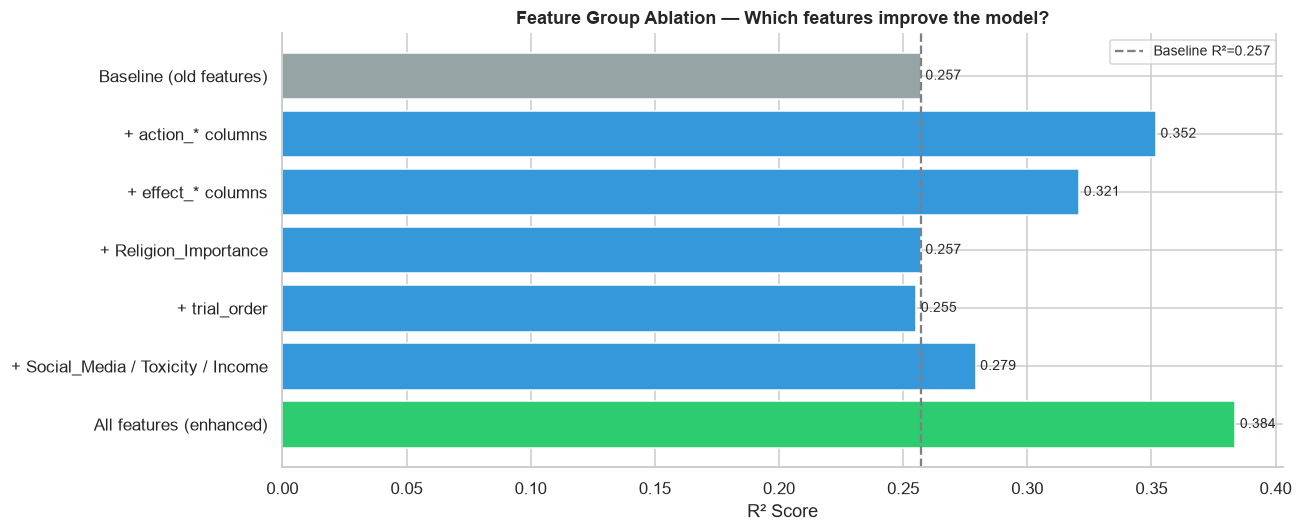

Saved: outputs/fig_ablation_enhanced.png


In [18]:
# Visualize ablation results
fig, ax = plt.subplots(figsize=(12, 5))

colors = ['#95a5a6'] + ['#3498db'] * 5 + ['#2ecc71']
bars = ax.barh(ablation_df['Model'][::-1], ablation_df['R²'][::-1],
               color=colors[::-1], edgecolor='white')
ax.bar_label(bars, labels=[f"{v:.3f}" for v in ablation_df['R²'][::-1]],
             padding=3, fontsize=9)
ax.set_xlabel("R² Score")
ax.set_title("Feature Group Ablation — Which features improve the model?",
             fontweight='bold', fontsize=12)
ax.axvline(r2_base, color='gray', linestyle='--', linewidth=1.5,
           label=f'Baseline R²={r2_base:.3f}')
ax.legend(fontsize=9)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig("outputs/fig_ablation_enhanced.png", bbox_inches='tight')
plt.show()
print("Saved: outputs/fig_ablation_enhanced.png")

## 10. Summary

### What we did
1. Added new feature groups: action_*, effect_*, Religion_Importance, trial_order, Social_Media_Frequency, Toxicity_Experience, Income
2. Re-ran linear regression with all features
3. Ran ablation study to identify which new features contributed most

### How to interpret results
- **Ablation plot** shows which feature group improved R² the most
- **Feature importance plot** shows which specific features the model relies on
- If `action_*` or `effect_*` features have large coefficients → prompt harm type matters
- If `trial_order` has a large coefficient → annotator fatigue/order effects are real

### Next steps
- [ ] Add interaction terms (e.g., Factor_1 × Harm_Level)
- [ ] Try Random Forest with enhanced features
- [ ] Mixed-effects model (annotator as random effect)


In [20]:
print("Final comparison:")
print(f"  Baseline model  : R²={r2_base:.3f}  RMSE={rmse_base:.2f}")
print(f"  Enhanced model  : R²={r2_enh:.3f}  RMSE={rmse_enh:.2f}")
print()
print("Output files:")
for f in sorted(os.listdir("outputs")):
    if f.endswith('.png') and ('ablation' in f or 'enhanced' in f):
        size = os.path.getsize(os.path.join("outputs", f)) / 1024
        print(f"  {f:<50} ({size:.1f} KB)")

Final comparison:
  Baseline model  : R²=0.257  RMSE=32.42
  Enhanced model  : R²=0.384  RMSE=29.52

Output files:
  fig_ablation_enhanced.png                          (43.2 KB)
  fig_enhanced_features.png                          (73.4 KB)
